In [1]:
# Uncomment if needed:
# %pip install numpy scipy pandas matplotlib scikit-image scikit-learn tifffile

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter
from scipy.optimize import minimize
from scipy.special import logsumexp
from scipy.stats import norm
from sklearn.mixture import GaussianMixture
from skimage import io, measure, morphology, color, img_as_float
from skimage.segmentation import find_boundaries
import warnings


In [2]:
INPUT_DIR = Path('images')
OUTPUT_DIR = Path('spatial_gmm_results')
K = 3
MIN_AREA = 3                  # minimum connected-component area, pixels
CONNECTIVITY = 2             # 8-connected pixels
FOREGROUND_CLASSES = 1       # 1 = brightest class; 2 = two brightest classes
MAX_FIT_PIXELS = 120_000     # optimization subset; all pixels labeled afterward
MAX_ITER = 35
TOL = 1e-5
SEED = 42
SHOW_FIGURES = True
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

files = sorted(p for p in INPUT_DIR.iterdir() if p.is_file() and p.suffix.lower() in {'.tif', '.tiff'}) if INPUT_DIR.exists() else []
if len(files) != 4:
    raise ValueError(f'Expected exactly 4 TIFF images in {INPUT_DIR.resolve()}, found {len(files)}: {[p.name for p in files]}')

print('Images:', *[p.name for p in files], sep='\n  ')


Images:
  img1.tif
  img2.tif
  img3.tif
  img4.tif


In [3]:
def load_image(path):
    raw = io.imread(path)
    if raw.ndim == 3 and raw.shape[-1] in (3, 4):
        raw = color.rgb2gray(raw[..., :3])
    if raw.ndim != 2:
        raise ValueError(f'{path.name}: expected 2D grayscale, got shape {raw.shape}')
    raw = raw.astype(np.float64)
    if not np.isfinite(raw).all():
        raise ValueError(f'{path.name}: contains NaN/Inf')
    lo, hi = float(raw.min()), float(raw.max())
    if hi <= lo:
        raise ValueError(f'{path.name}: constant-intensity image')
    return raw, (raw - lo) / (hi - lo)


In [4]:
def spatial_log_prior(img, c, b):
    # Eq. (12)-(13): neighborhood average of EXPONENTIAL weights,
    # not exponential of neighborhood-averaged intensity.
    logw = []
    for cj, bj in zip(c, b):
        weights = np.exp(-0.5 * ((img - cj) / max(bj, 1e-4)) ** 2)
        local = uniform_filter(weights, size=3, mode='reflect')
        logw.append(np.log(np.maximum(local, 1e-300)))
    logw = np.stack(logw, axis=-1)
    return logw - logsumexp(logw, axis=-1, keepdims=True)


def posterior(img, mu, sigma, c, b):
    logpi = spatial_log_prior(img, c, b)
    loglike = norm.logpdf(img[..., None], loc=mu, scale=sigma)
    logjoint = logpi + loglike
    return np.exp(logjoint - logsumexp(logjoint, axis=-1, keepdims=True))


def fit_spatial_gmm(img, k=3, max_fit_pixels=120_000, max_iter=35,
                    tol=1e-5, seed=42):
    rng = np.random.default_rng(seed)
    flat = img.ravel()
    n = flat.size
    fit_idx = (rng.choice(n, size=max_fit_pixels, replace=False)
               if max_fit_pixels is not None and n > max_fit_pixels
               else np.arange(n))
    x = flat[fit_idx]
    init = GaussianMixture(n_components=k, random_state=seed,
                           n_init=5, reg_covar=1e-5, max_iter=200).fit(x[:, None])
    order = np.argsort(init.means_.ravel())
    mu = init.means_.ravel()[order].copy()
    sigma = np.sqrt(init.covariances_.reshape(-1)[order]).clip(0.01, 0.5)
    c, b = mu.copy(), sigma.copy().clip(0.02, 0.5)
    history = []

    for iteration in range(max_iter):
        # E-step, computed with full 2D spatial context, then subset for fitting.
        r = posterior(img, mu, sigma, c, b).reshape(-1, k)[fit_idx]
        nk = np.maximum(r.sum(axis=0), 1e-10)
        mu_new = np.sum(r * x[:, None], axis=0) / nk
        sigma_new = np.sqrt(np.sum(r * (x[:, None] - mu_new) ** 2, axis=0) / nk).clip(0.01, 0.5)

        # Spatial M-step: maximize sum_ij r_ij log(pi_ij).
        # Fixed responsibilities = generalized EM update of the paper's Q-function.
        def objective(theta):
            cc, bb = theta[:k], theta[k:]
            logpi_sample = spatial_log_prior(img, cc, bb).reshape(-1, k)[fit_idx]
            return -np.sum(r * logpi_sample) / len(x)

        bounds = [(0.0, 1.0)] * k + [(0.01, 0.75)] * k
        result = minimize(objective, np.r_[c, b], method='L-BFGS-B',
                          bounds=bounds, options={'maxiter': 15, 'ftol': 1e-8})
        c_new, b_new = result.x[:k], result.x[k:]
        delta = max(np.max(np.abs(mu_new-mu)), np.max(np.abs(sigma_new-sigma)),
                    np.max(np.abs(c_new-c)), np.max(np.abs(b_new-b)))
        mu, sigma, c, b = mu_new, sigma_new, c_new, b_new
        # Mean observed negative log-likelihood (for diagnostics).
        lp = spatial_log_prior(img, c, b).reshape(-1, k)[fit_idx]
        ll = norm.logpdf(x[:, None], loc=mu, scale=sigma)
        nll = -np.mean(logsumexp(lp + ll, axis=1))
        history.append({'iteration': iteration + 1, 'nll': nll, 'max_change': delta})
        if delta < tol:
            break

    # Sort by mean intensity for consistent labels (0=darkest).
    order = np.argsort(mu)
    mu, sigma, c, b = mu[order], sigma[order], c[order], b[order]
    prob = posterior(img, mu, sigma, c, b)
    return {'probabilities': prob, 'classes': prob.argmax(axis=-1),
            'mu': mu, 'sigma': sigma, 'c': c, 'b': b,
            'history': pd.DataFrame(history)}


In [5]:
def fit_standard_gmm(img, k=3, max_fit_pixels=120_000, seed=42):
    rng = np.random.default_rng(seed)
    flat = img.ravel()
    idx = rng.choice(flat.size, max_fit_pixels, replace=False) if max_fit_pixels and flat.size > max_fit_pixels else np.arange(flat.size)
    model = GaussianMixture(n_components=k, random_state=seed, n_init=5,
                            reg_covar=1e-5, max_iter=200).fit(flat[idx, None])
    order = np.argsort(model.means_.ravel())
    prob = model.predict_proba(flat[:, None])[:, order].reshape(*img.shape, k)
    return {'classes': prob.argmax(axis=-1), 'probabilities': prob,
            'mu': model.means_.ravel()[order]}


def get_mask_and_labels(classes, k=3, foreground_classes=1, min_area=3):
    mask = classes >= k - foreground_classes
    mask = morphology.remove_small_objects(mask, min_size=min_area, connectivity=CONNECTIVITY)
    labels = measure.label(mask, connectivity=CONNECTIVITY)
    return mask, labels


def measure_rois(raw, labels, filename, method):
    props = measure.regionprops_table(labels, intensity_image=raw,
        properties=('label', 'area', 'centroid', 'equivalent_diameter_area',
                    'perimeter', 'solidity', 'mean_intensity', 'max_intensity'))
    df = pd.DataFrame(props)
    df.insert(0, 'image', filename)
    df.insert(1, 'method', method)
    return df


def plot_comparison(raw, normalized, baseline, spatial, baseline_labels,
                    spatial_labels, filename, output_dir, show=True):
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    axes[0,0].imshow(raw, cmap='gray'); axes[0,0].set_title('Original (raw intensity)')
    axes[0,1].imshow(baseline['classes'], cmap='viridis', vmin=0, vmax=K-1)
    axes[0,1].set_title('Standard GMM classes')
    axes[0,2].imshow(spatial['classes'], cmap='viridis', vmin=0, vmax=K-1)
    axes[0,2].set_title('Spatial GMM classes')
    axes[1,0].hist(normalized.ravel(), bins=120, color='gray')
    for j, mu in enumerate(spatial['mu']):
        axes[1,0].axvline(mu, linestyle='--', label=f'Class {j}: {mu:.3f}')
    axes[1,0].set_title('Normalized intensity histogram')
    axes[1,0].set_yscale('log'); axes[1,0].legend(fontsize=8)
    for ax, labels, name in [(axes[1,1], baseline_labels, 'Standard GMM'),
                             (axes[1,2], spatial_labels, 'Spatial GMM')]:
        ax.imshow(raw, cmap='gray')
        boundary = find_boundaries(labels, mode='outer')
        overlay = np.zeros((*raw.shape, 4), dtype=float)
        overlay[boundary] = [1, 0, 0, 1]
        ax.imshow(overlay)
        ax.set_title(f'{name}: {labels.max()} ROIs')
    for ax in axes.flat:
        if ax is not axes[1,0]: ax.axis('off')
    fig.suptitle(filename, fontsize=14)
    fig.tight_layout()
    fig.savefig(output_dir / f'{Path(filename).stem}_comparison.png', dpi=160, bbox_inches='tight')
    if show: plt.show()
    plt.close(fig)


[1/4] img1.tif


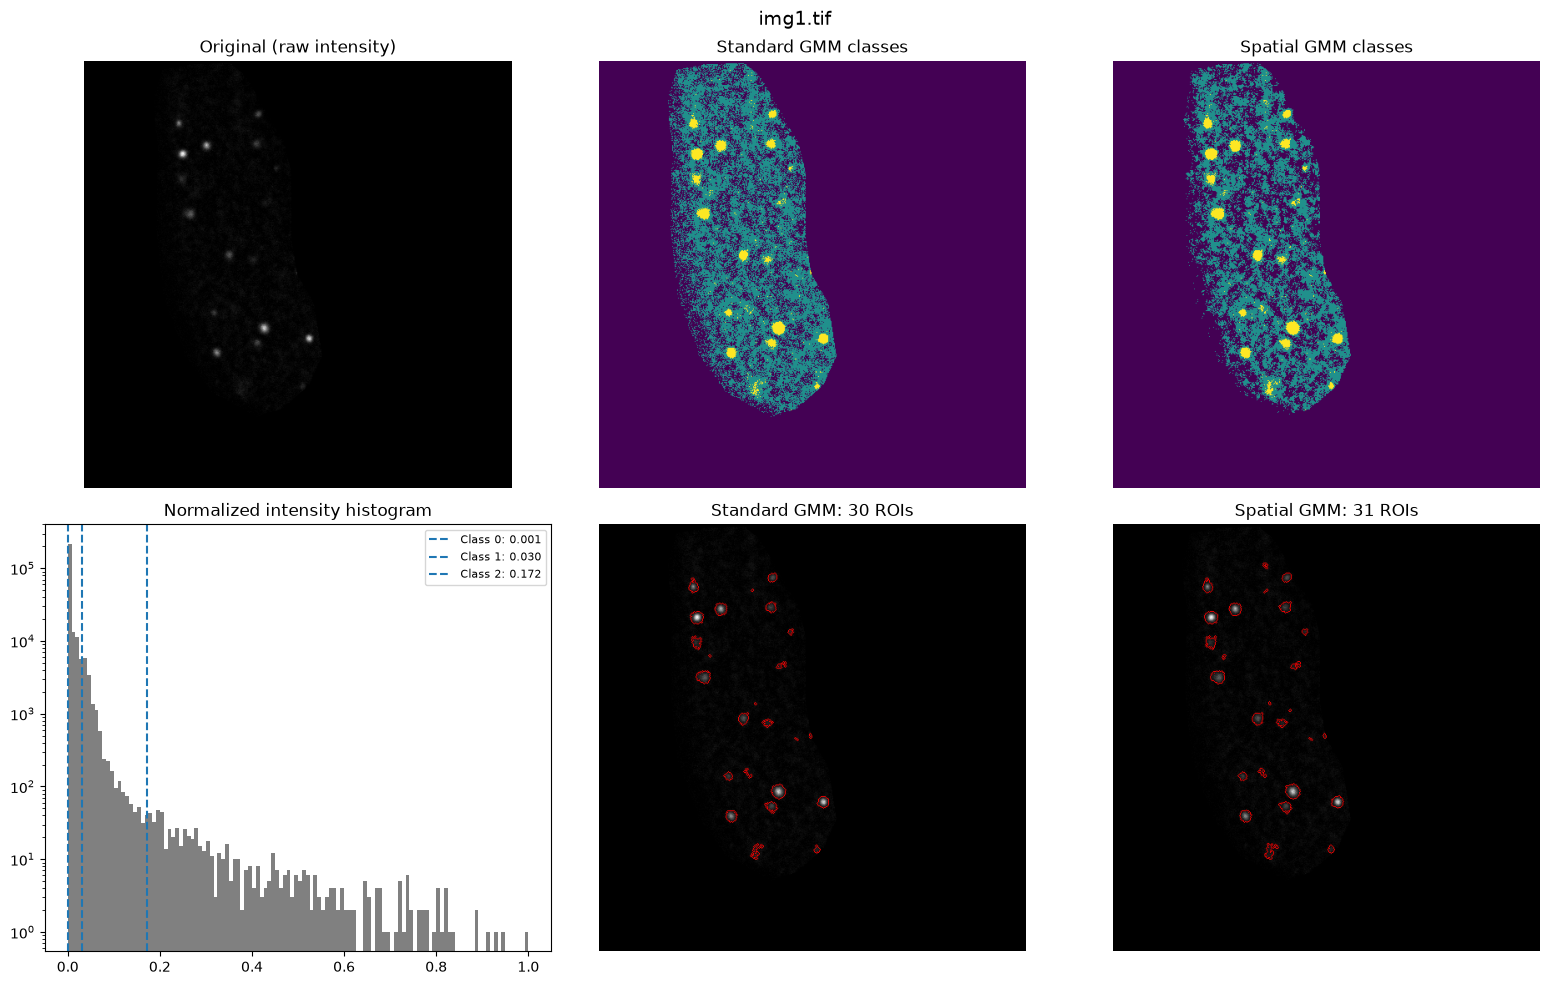

[2/4] img2.tif


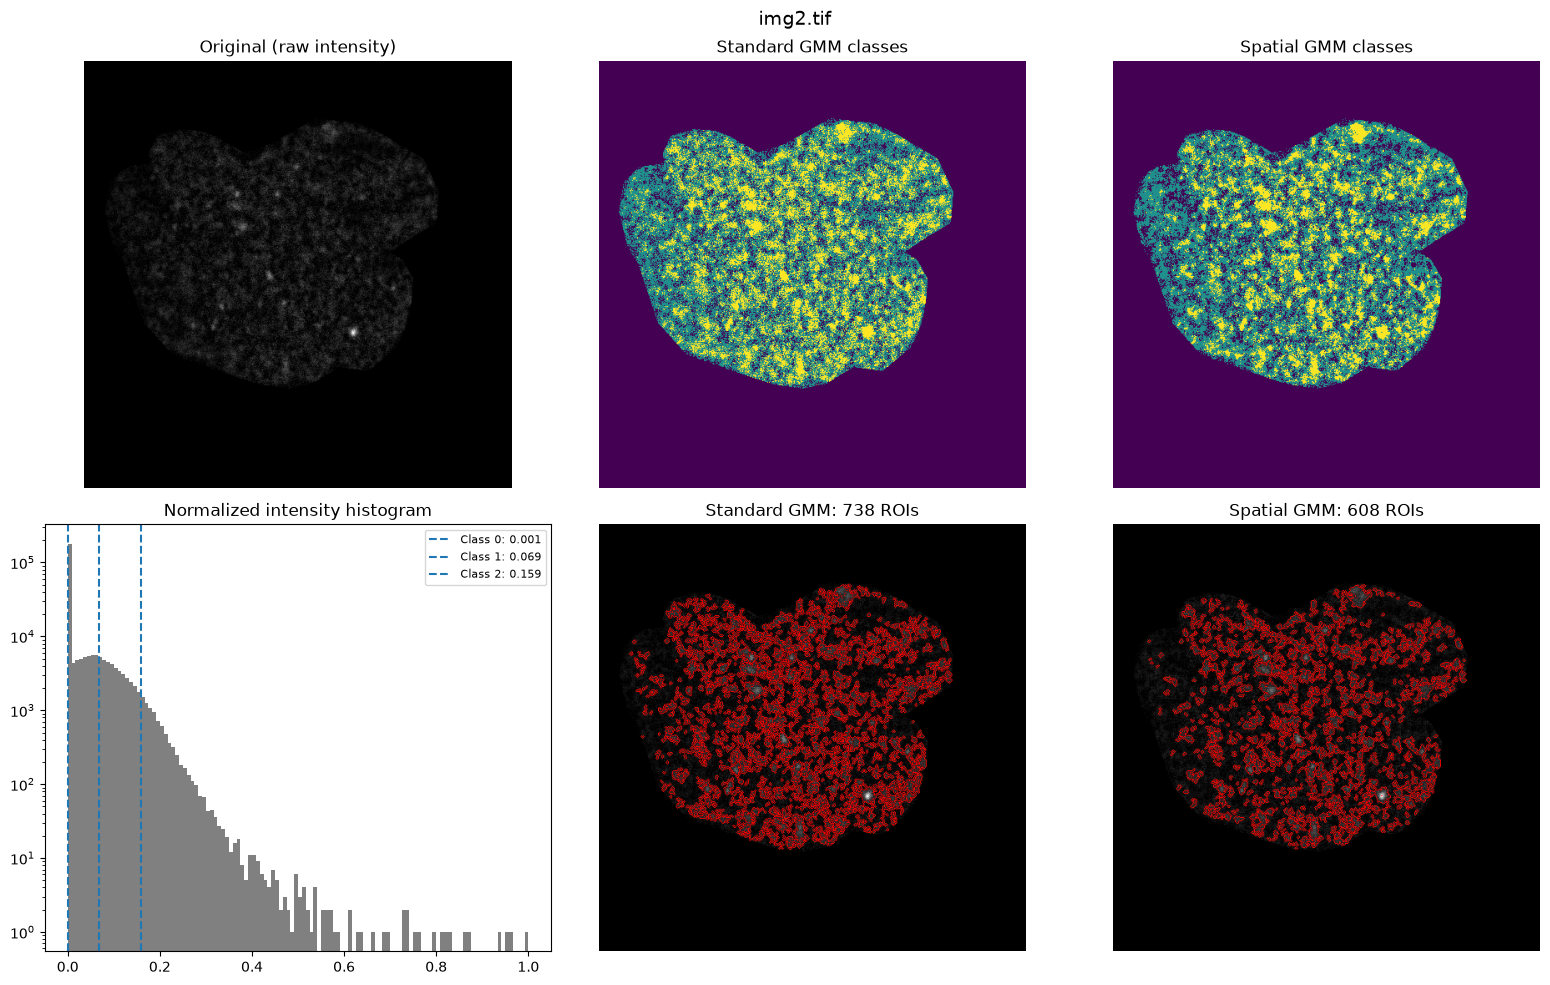

[3/4] img3.tif


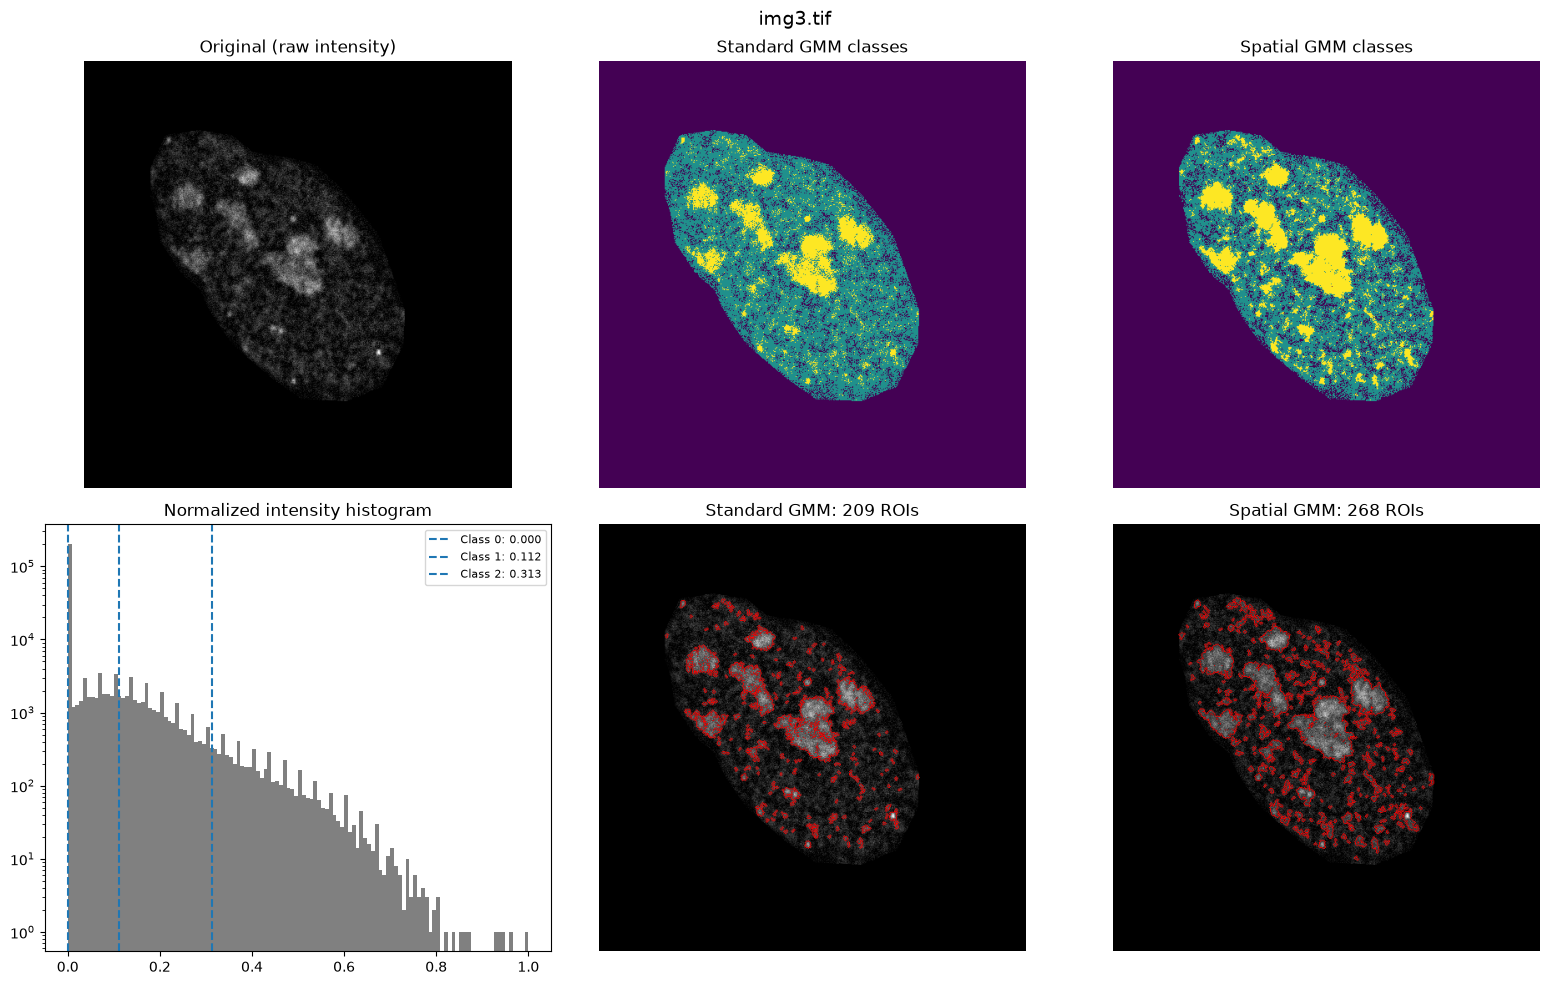

[4/4] img4.tif


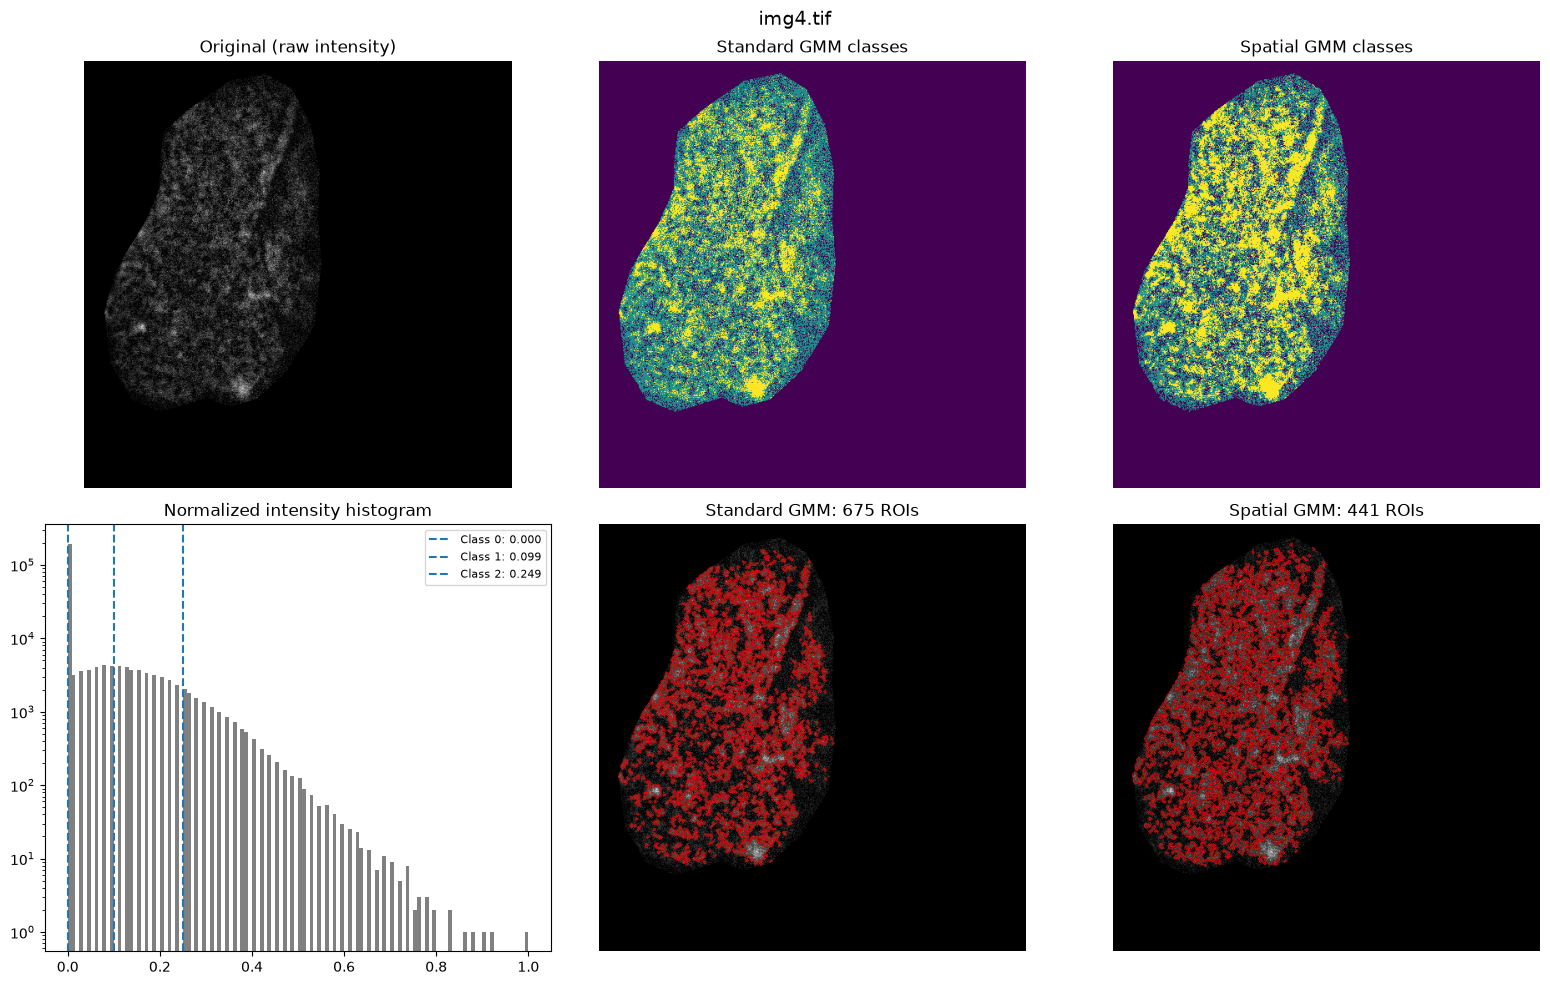

,image,method,n_rois,foreground_area_px,foreground_fraction,mean_roi_area_px
0,img1.tif,standard,30,1736,0.006622,57.866667
1,img1.tif,spatial,31,1978,0.007545,63.806452
2,img2.tif,standard,738,21694,0.082756,29.395664
3,img2.tif,spatial,608,17535,0.066891,28.840461
4,img3.tif,standard,209,8224,0.031372,39.349282
5,img3.tif,spatial,268,13095,0.049953,48.861940
6,img4.tif,standard,675,16217,0.061863,24.025185
7,img4.tif,spatial,441,25863,0.098660,58.646259


Saved results to: /home/lopatushka/LLPS/Foci/FOCI_GMM/spatial_gmm_results


In [6]:
all_rois = []
summary = []
models = {}

for index, path in enumerate(files, 1):
    print(f'[{index}/4] {path.name}')
    raw, img = load_image(path)
    baseline = fit_standard_gmm(img, k=K, max_fit_pixels=MAX_FIT_PIXELS, seed=SEED)
    spatial = fit_spatial_gmm(img, k=K, max_fit_pixels=MAX_FIT_PIXELS,
                              max_iter=MAX_ITER, tol=TOL, seed=SEED)
    models[path.name] = spatial
    for method, model in [('standard', baseline), ('spatial', spatial)]:
        mask, labels = get_mask_and_labels(model['classes'], k=K,
                            foreground_classes=FOREGROUND_CLASSES, min_area=MIN_AREA)
        model['mask'], model['labels'] = mask, labels
        io.imsave(OUTPUT_DIR / f'{index:02d}_{path.stem}_{method}_mask.tif',
                  (mask.astype(np.uint8) * 255), check_contrast=False)
        io.imsave(OUTPUT_DIR / f'{index:02d}_{path.stem}_{method}_labels.tif',
                  labels.astype(np.int32), check_contrast=False)
        io.imsave(OUTPUT_DIR / f'{index:02d}_{path.stem}_{method}_classes.tif',
                  model['classes'].astype(np.uint8), check_contrast=False)
        df = measure_rois(raw, labels, path.name, method)
        df.to_csv(OUTPUT_DIR / f'{index:02d}_{path.stem}_{method}_ROIs.csv', index=False)
        all_rois.append(df)
        summary.append({'image': path.name, 'method': method,
                        'n_rois': int(labels.max()), 'foreground_area_px': int(mask.sum()),
                        'foreground_fraction': float(mask.mean()),
                        'mean_roi_area_px': float(df['area'].mean()) if len(df) else np.nan})
    spatial['history'].to_csv(OUTPUT_DIR / f'{index:02d}_{path.stem}_convergence.csv', index=False)
    plot_comparison(raw, img, baseline, spatial, baseline['labels'], spatial['labels'],
                    path.name, OUTPUT_DIR, show=SHOW_FIGURES)

summary_df = pd.DataFrame(summary)
rois_df = pd.concat(all_rois, ignore_index=True)
summary_df.to_csv(OUTPUT_DIR / 'summary.csv', index=False)
rois_df.to_csv(OUTPUT_DIR / 'all_ROIs.csv', index=False)
display(summary_df)
print('Saved results to:', OUTPUT_DIR.resolve())


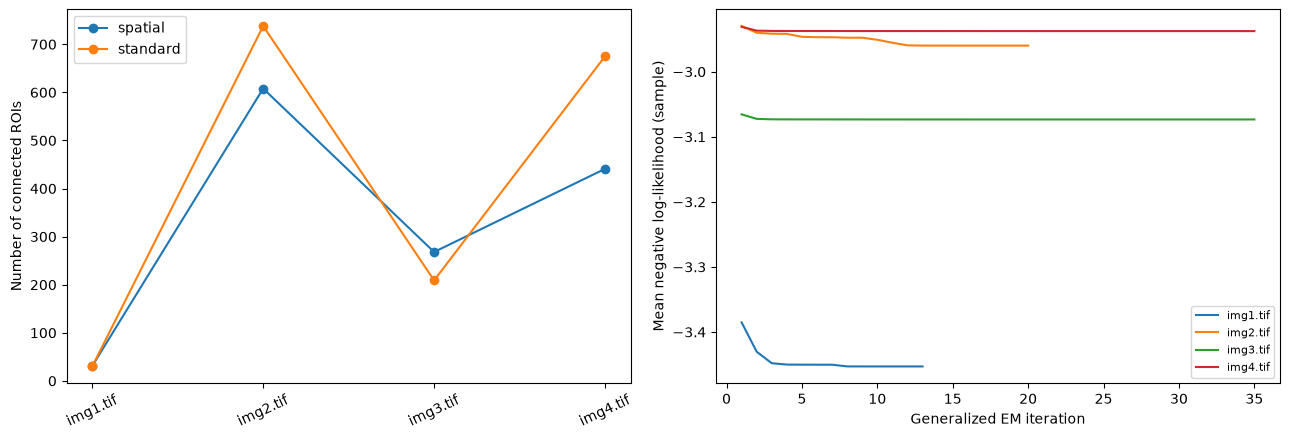

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for method, grp in summary_df.groupby('method'):
    axes[0].plot(grp['image'], grp['n_rois'], 'o-', label=method)
axes[0].set_ylabel('Number of connected ROIs')
axes[0].tick_params(axis='x', rotation=25)
axes[0].legend()
for name, model in models.items():
    axes[1].plot(model['history']['iteration'], model['history']['nll'], label=name)
axes[1].set_xlabel('Generalized EM iteration')
axes[1].set_ylabel('Mean negative log-likelihood (sample)')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()